# LLMコード生成によるロボットアーム制御実験（Mac版）

人間が作業内容の変化（障害物の追加）を伝え、LLMが制御コードを書き、検証を通ったものだけをシミュレータで実行します。シミュレータは **MuJoCo** です。Apple Silicon（Mac mini M6など）のMacで、JupyterLabから実行します。

**使い方**：上の節から順に実行してください。手順書との対応は次の通りです（§は下の見出しの番号）。

| 手順書 | このNotebook | 内容 |
| --- | --- | --- |
| 手順1 | §1〜§2 | 環境の確認、保存先、APIキー |
| 手順2 | §3〜§5 | 検証関数、シミュレータ、動作確認（3Dビューアの準備を含む） |
| 手順3 | §6〜§10 | シナリオ、プロンプト、コード生成、実験ランナー、配線の確認 |
| 手順5 | §11〜§13、付録 | 基本コードの作成、全条件の実行、集計、生成コードを読む |
| 手順6 | §14 | 動画の作成 |

結果はすべて `~/llm_arm` に保存されます。Notebookを閉じても、続きから再開できます。

## 1. 環境の確認

ライブラリは手順書の手順1でターミナルから入れてあります。ここでは、Apple Silicon用のPythonで動いているか、必要なライブラリと日本語フォントがそろっているかを確かめます。

MuJoCoは、macOSでは画面を出さない描画（CGL）を自動で使うので、描画の設定は要りません。

In [1]:
import os, sys, platform, shutil, subprocess, unicodedata

if platform.system() == "Darwin" and platform.machine() != "arm64":
    raise RuntimeError("x86_64版（Rosetta）のPythonで動いています。MuJoCoはApple Silicon用（arm64）のPythonが必要です。手順書の手順1を見直してください。")
if shutil.which("ffmpeg") is None:
    print("注意：ffmpeg が見つかりません。動画の保存に必要です（brew install ffmpeg）")

import mujoco, mediapy as media
from PIL import ImageFont


def find_font():
    """日本語フォントを探す。macOSはヒラギノ角ゴシック、なければ他の候補。"""
    mac_dirs = ["/System/Library/Fonts", "/Library/Fonts", os.path.expanduser("~/Library/Fonts")]
    for d in mac_dirs:
        if not os.path.isdir(d):
            continue
        for weight in ("W4", "W3", "W5", "W6"):
            for name in sorted(os.listdir(d)):
                # macOSのファイル名は濁点が分かれた形（NFD）のことがあるので、そろえて比べる
                if unicodedata.normalize("NFC", name) == f"ヒラギノ角ゴシック {weight}.ttc":
                    return os.path.join(d, name)
    for p in ["/System/Library/Fonts/Hiragino Sans GB.ttc",
              "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"]:
        if os.path.exists(p):
            return p
    return None

FONT_PATH = find_font()        # 見つからない場合は、日本語フォントのパスをここに直接書く
if FONT_PATH is None:
    raise RuntimeError("日本語フォントが見つかりません。FONT_PATH に .ttc か .ttf のパスを書いてください。")

def _font_index(name):
    for i in range(12):
        try:
            if ImageFont.truetype(FONT_PATH, 12, index=i).getname()[0] == name:
                return i
        except OSError:
            break
    return 0
FONT_SANS = _font_index("Noto Sans CJK JP")                 # ヒラギノでは 0 になる
FONT_MONO = _font_index("Noto Sans Mono CJK JP") if "Noto" in FONT_PATH else FONT_SANS

print(f"Python {platform.python_version()}（{platform.machine()}） / MuJoCo {mujoco.__version__}")
print(f"フォント: {FONT_PATH}")

Python 3.12.16（arm64） / MuJoCo 3.17.0
フォント: /System/Library/Fonts/ヒラギノ角ゴシック W4.ttc


## 2. 保存先とAPIキー

結果はホームフォルダの `llm_arm` に保存します（手順1で作ったフォルダ）。

APIキーは、`~/llm_arm/.env` に `ANTHROPIC_API_KEY=sk-ant-...` の1行を書いておくと、ここで読み込みます。ファイルがなければ入力欄が出るので、そこに貼り付けてください。キーがなくても、手順3の配線確認（ダミーLLM）までは進めます。

In [2]:
OUT = os.path.expanduser("~/llm_arm")                # 保存先。プロンプトを変えて比べるときは別名にする
MODEL = os.environ.get("LLM_MODEL", "claude-sonnet-5-5")

for sub in ["runs", "videos"]:
    os.makedirs(f"{OUT}/{sub}", exist_ok=True)
RESULTS = f"{OUT}/results.jsonl"
BASE_FILE = f"{OUT}/base_plan.py"

# APIキー：環境変数 → ~/llm_arm/.env → 入力欄 の順に探す
env_file = os.path.expanduser("~/llm_arm/.env")
if not os.environ.get("ANTHROPIC_API_KEY") and os.path.exists(env_file):
    for line in open(env_file, encoding="utf-8"):
        if line.strip().startswith("ANTHROPIC_API_KEY="):
            os.environ["ANTHROPIC_API_KEY"] = line.split("=", 1)[1].strip().strip('"').strip("'")
if not os.environ.get("ANTHROPIC_API_KEY") and not os.environ.get("SKIP_KEY_PROMPT"):
    from getpass import getpass
    key = getpass("APIキー（配線確認だけなら空のままEnter）: ").strip()
    if key:
        os.environ["ANTHROPIC_API_KEY"] = key

print("保存先:", OUT, "/ モデル:", MODEL,
      "/ APIキー:", "あり" if os.environ.get("ANTHROPIC_API_KEY") else "なし")

保存先: /Users/YoshiGoto/llm_arm / モデル: claude-sonnet-5-5 / APIキー: あり


## 3. アームの仕様と検証関数

アームは水平面で動く2関節の平面アームです（リンク長 0.5 m と 0.4 m、太さ 4 cm）。LLMが書いた計画（関節角の経由点のリスト）を、実行前にこの関数で検査します。

- 経由点の間は関節空間で直線補間して動かすので、検証も同じ補間を0.01 radの刻みで再現する
- 各姿勢で、リンク（線分）と障害物（円）の距離が「半径＋リンクの半幅 2 cm＋安全余裕 2 cm」を下回れば接触とみなす
- ほかに、可動範囲（±2.98 rad）と、最終位置の誤差（1 cm以内）を確かめる

In [3]:
import math

L1, L2 = 0.5, 0.4          # リンク長 [m]
LINK_HALF_WIDTH = 0.02     # リンクの半幅 [m]
SAFETY = 0.02              # 安全余裕 [m]
Q_LIMIT = math.pi * 0.95   # 関節の可動範囲 [rad]
GOAL_TOL = 0.01            # 先端の到達誤差の許容値 [m]
STEP = 0.01                # 経路を調べる刻み [rad]


def fk(q1, q2):
    """順運動学：肘と先端の位置を返す。"""
    ex, ey = L1 * math.cos(q1), L1 * math.sin(q1)
    tx, ty = ex + L2 * math.cos(q1 + q2), ey + L2 * math.sin(q1 + q2)
    return (ex, ey), (tx, ty)


def seg_point_dist(a, b, p):
    """線分abと点pの距離。"""
    ax, ay = a; bx, by = b; px, py = p
    dx, dy = bx - ax, by - ay
    L = dx * dx + dy * dy
    t = 0.0 if L == 0 else max(0.0, min(1.0, ((px - ax) * dx + (py - ay) * dy) / L))
    cx, cy = ax + t * dx, ay + t * dy
    return math.hypot(px - cx, py - cy)


def collides(q1, q2, obstacles):
    elbow, tip = fk(q1, q2)
    for ob in obstacles:
        c, r = (ob["x"], ob["y"]), ob["r"]
        clear = r + LINK_HALF_WIDTH + SAFETY
        if seg_point_dist((0, 0), elbow, c) < clear or seg_point_dist(elbow, tip, c) < clear:
            return True
    return False


def interpolate(waypoints, start):
    """関節空間で直線補間した経路を返す（実行時と同じ補間）。"""
    path, prev = [start], start
    for wp in waypoints:
        n = max(1, int(max(abs(wp[0] - prev[0]), abs(wp[1] - prev[1])) / STEP))
        for i in range(1, n + 1):
            path.append((prev[0] + (wp[0] - prev[0]) * i / n,
                         prev[1] + (wp[1] - prev[1]) * i / n))
        prev = wp
    return path


def verify(waypoints, target, obstacles, start=(0.0, 0.0)):
    """合格なら (True, '')、不合格なら (False, 理由) を返す。"""
    if not waypoints:
        return False, "経由点が空です"
    for i, wp in enumerate(waypoints):
        if len(wp) != 2 or not all(isinstance(v, (int, float)) and math.isfinite(v) for v in wp):
            return False, f"経由点{i}が不正です: {wp}"
        if abs(wp[0]) > Q_LIMIT or abs(wp[1]) > Q_LIMIT:
            return False, f"経由点{i}が可動範囲（±{Q_LIMIT:.2f} rad）を超えています: {wp}"
    for q in interpolate(waypoints, start):
        if collides(q[0], q[1], obstacles):
            _, tip = fk(*q)
            return False, (f"経路の途中で障害物に接触します（q1={q[0]:.2f}, q2={q[1]:.2f}, "
                           f"先端=({tip[0]:.2f}, {tip[1]:.2f})）")
    _, tip = fk(*waypoints[-1])
    err = math.hypot(tip[0] - target[0], tip[1] - target[1])
    if err > GOAL_TOL:
        return False, f"最終位置の誤差が {err * 100:.1f} cm で、許容値 1 cm を超えています"
    return True, ""

## 4. シミュレータ（MuJoCo）

アーム、障害物、目標の目印をMJCF（MuJoCoのモデル記述）で定義します。旧版のGazeboのSDFと同じ寸法です。

- 関節ごとに位置制御のアクチュエータを置き、指令した角度へ動かす
- 経由点の間を毎秒1 radの速さで補間し、50 Hzで指令を更新する
- アームが障害物に触れると、障害物が黄色に変わり、接触として記録される
- LLMが想定した障害物の位置は、半透明の円柱で表示できる（あいまいな指示のとき）

このセルは、3Dビューアで見るためのモデル（`arm.xml`）と再生スクリプト（`view_run.py`）も `~/llm_arm` に書き出します。

In [4]:
import math
import numpy as np
import mujoco


ARM_XML = f"""
<mujoco model="planar_arm">
  <compiler angle="radian"/>
  <option timestep="0.002" gravity="0 0 -9.81"/>
  <visual>
    <global offwidth="1280" offheight="720"/>
    <quality shadowsize="4096"/>
    <headlight ambient="0.25 0.25 0.25" diffuse="0.15 0.15 0.15" specular="0 0 0"/>
  </visual>
  <asset>
    <texture name="grid" type="2d" builtin="checker" rgb1="0.80 0.80 0.78" rgb2="0.72 0.72 0.70"
             width="300" height="300" mark="edge" markrgb="0.7 0.7 0.68"/>
    <material name="table" texture="grid" texrepeat="16 16" reflectance="0"/>
  </asset>
  <worldbody>
    <light directional="true" pos="0 0 3" dir="0.15 0.25 -1" diffuse="0.5 0.5 0.5" specular="0.05 0.05 0.05"/>
    <light directional="true" pos="0 0 3" dir="-0.3 -0.2 -1" diffuse="0.15 0.15 0.15" specular="0 0 0" castshadow="false"/>
    <camera name="overview" pos="0.05 -1.25 1.85" xyaxes="1 0 0 0 0.82 0.57"/>
    <camera name="top" pos="0.0 0.15 3.6" xyaxes="1 0 0 0 1 0" fovy="35"/>
    <!-- 作業台（見た目だけ。接触はしない） -->
    <geom name="table" type="box" pos="0 0.1 0.05" size="1.6 1.6 0.05" material="table"
          contype="0" conaffinity="0"/>
    <!-- 目標の目印（見た目だけ） -->
    <body name="target_marker" pos="0.30 0.60 0.105">
      <geom type="cylinder" size="0.03 0.004" rgba="0.1 0.7 0.2 1" contype="0" conaffinity="0"/>
      <!-- 先端と同じ高さに半透明の球を置き、到達がひと目でわかるようにする -->
      <geom type="sphere" pos="0 0 0.155" size="0.035" rgba="0.1 0.8 0.2 0.35" contype="0" conaffinity="0"/>
      <geom type="cylinder" pos="0 0 0.078" size="0.003 0.075" rgba="0.1 0.7 0.2 0.5" contype="0" conaffinity="0"/>
    </body>
    <!-- 障害物：半径5 cm、高さ40 cmの円柱。最初は画面外 -->
    <body name="obstacle" pos="3 3 0.3">
      <geom name="obstacle" type="cylinder" size="0.05 0.2" rgba="0.85 0.15 0.1 1"/>
    </body>
    <!-- LLMが想定した障害物の位置（あいまい指示のときだけ表示。接触はしない） -->
    <body name="ghost" pos="3 3 0.3">
      <geom name="ghost" type="cylinder" size="0.05 0.2" rgba="0.9 0.5 0.5 0.3" contype="0" conaffinity="0"/>
    </body>
    <!-- アーム -->
    <body name="base" pos="0 0 0.15">
      <geom type="cylinder" size="0.06 0.05" rgba="0.3 0.3 0.3 1" contype="0" conaffinity="0"/>
      <body name="link1" pos="0 0 0.07">
        <joint name="joint1" type="hinge" axis="0 0 1" range="-2.98 2.98" damping="12" armature="0.01"/>
        <geom name="link1" type="box" pos="{L1 / 2} 0 0" size="{L1 / 2} 0.02 0.02"
              rgba="0.15 0.35 0.8 1" mass="1.0"/>
        <body name="link2" pos="{L1} 0 0.04">
          <joint name="joint2" type="hinge" axis="0 0 1" range="-2.98 2.98" damping="3" armature="0.005"/>
          <geom name="link2" type="box" pos="{L2 / 2} 0 0" size="{L2 / 2} 0.02 0.02"
                rgba="0.2 0.6 0.9 1" mass="0.6"/>
          <geom name="tip" type="sphere" pos="{L2} 0 0" size="0.025" rgba="1 0.75 0.1 1"
                contype="0" conaffinity="0" mass="0.01"/>
          <site name="tip" pos="{L2} 0 0" size="0.005"/>
        </body>
      </body>
    </body>
  </worldbody>
  <contact>
    <exclude body1="base" body2="link2"/>
  </contact>
  <actuator>
    <position name="joint1" joint="joint1" kp="100" ctrlrange="-2.98 2.98"/>
    <position name="joint2" joint="joint2" kp="50" ctrlrange="-2.98 2.98"/>
  </actuator>
</mujoco>
"""

CONTROL_HZ = 50          # 指令を更新する周期
MAX_JOINT_SPEED = 1.0    # 経由点の間を動かす速さ [rad/s]
SETTLE_SEC = 1.0         # 最後の指令のあと、止まるまで待つ時間
FPS = 30                 # 動画のフレームレート
OBSTACLE_RGBA = np.array([0.85, 0.15, 0.1, 1.0])
CONTACT_RGBA = np.array([1.0, 0.9, 0.0, 1.0])


class ArmSim:
    def __init__(self, width=640, height=480, render=True):
        self.model = mujoco.MjModel.from_xml_string(ARM_XML)
        self.data = mujoco.MjData(self.model)
        self.renderer = mujoco.Renderer(self.model, height=height, width=width) if render else None
        m = self.model
        self.obstacle_body = m.body("obstacle").id
        self.obstacle_geom = m.geom("obstacle").id
        self.target_body = m.body("target_marker").id
        self.ghost_body = m.body("ghost").id
        self.ghost_geom = m.geom("ghost").id
        self.arm_geoms = {m.geom("link1").id, m.geom("link2").id}
        self.tip_site = m.site("tip").id
        self.n_sub = round(1.0 / (CONTROL_HZ * m.opt.timestep))

    # --- 配置 ---
    def set_scene(self, target, obstacles, assumed=None):
        """目標の目印と障害物を置き、アームを開始姿勢 (0, 0) に戻す。
        assumed: LLMが想定した障害物（半透明で表示するだけ）"""
        m, d = self.model, self.data
        if assumed:
            m.body_pos[self.ghost_body][:2] = (assumed[0]["x"], assumed[0]["y"])
            m.geom_size[self.ghost_geom][0] = assumed[0]["r"]
        else:
            m.body_pos[self.ghost_body][:2] = (3.0, 3.0)
        m.body_pos[self.target_body][:2] = target
        if obstacles:
            o = obstacles[0]
            m.body_pos[self.obstacle_body][:2] = (o["x"], o["y"])
            m.geom_size[self.obstacle_geom][0] = o["r"]
        else:
            m.body_pos[self.obstacle_body][:2] = (3.0, 3.0)
        m.geom_rgba[self.obstacle_geom] = OBSTACLE_RGBA
        mujoco.mj_resetData(m, d)
        d.ctrl[:] = 0.0
        mujoco.mj_forward(m, d)

    def close(self):
        if self.renderer is not None:
            self.renderer.close()
            self.renderer = None

    # --- 状態 ---
    def q(self):
        return float(self.data.qpos[0]), float(self.data.qpos[1])

    def tip(self):
        return tuple(float(v) for v in self.data.site_xpos[self.tip_site][:2])

    def touching_obstacle(self):
        d = self.data
        for i in range(d.ncon):
            c = d.contact[i]
            pair = {c.geom1, c.geom2}
            if self.obstacle_geom in pair and pair & self.arm_geoms:
                return True
        return False

    # --- 描画 ---
    def frame(self, camera="overview"):
        self.renderer.update_scene(self.data, camera=camera)
        return self.renderer.render().copy()

    # --- 実行 ---
    def _joint_path(self, waypoints, start):
        """経由点の間を関節空間で直線補間した、制御周期ごとの指令列（検証と同じ経路）。"""
        step = MAX_JOINT_SPEED / CONTROL_HZ
        cmds, prev = [], start
        for wp in waypoints:
            n = max(1, math.ceil(max(abs(wp[0] - prev[0]), abs(wp[1] - prev[1])) / step))
            for i in range(1, n + 1):
                cmds.append((prev[0] + (wp[0] - prev[0]) * i / n, prev[1] + (wp[1] - prev[1]) * i / n))
            prev = wp
        cmds += [prev] * int(SETTLE_SEC * CONTROL_HZ)
        return cmds

    def execute(self, waypoints, target, obstacles, record=False, hold_sec=0.8, camera="overview",
                assumed=None):
        """障害物を置いた場面で、開始姿勢から経由点をたどって動かす。

        返り値: dict(最終誤差[cm], 接触したか, 接触時刻, フレーム列)
        """
        m, d = self.model, self.data
        self.set_scene(target, obstacles, assumed)
        frames, next_frame_t = [], 0.0
        first_contact = None

        def maybe_record():
            nonlocal next_frame_t
            if record and d.time + 1e-9 >= next_frame_t:
                frames.append(self.frame(camera))
                next_frame_t += 1.0 / FPS

        # 動き出す前に、場面を少し見せる
        for _ in range(int(hold_sec * CONTROL_HZ)):
            for _ in range(self.n_sub):
                mujoco.mj_step(m, d)
                maybe_record()

        for cmd in self._joint_path([tuple(w) for w in waypoints], (0.0, 0.0)):
            d.ctrl[:] = cmd
            for _ in range(self.n_sub):
                mujoco.mj_step(m, d)
                if self.touching_obstacle():
                    m.geom_rgba[self.obstacle_geom] = CONTACT_RGBA
                    if first_contact is None:
                        first_contact = d.time
                maybe_record()

        tx, ty = self.tip()
        err = math.hypot(tx - target[0], ty - target[1])
        return {"tip_error_cm": round(err * 100, 2), "contact": first_contact is not None,
                "contact_time": first_contact, "final_q": self.q(), "frames": frames}


SIM = ArmSim()

# 3Dビューア用：モデルと再生スクリプトを保存先に書き出す（ターミナルから mjpython で使う）
with open(f"{OUT}/arm.xml", "w", encoding="utf-8") as f:
    f.write(ARM_XML)
VIEW_RUN = r'''"""MuJoCoの3Dビューアで、場面や記録した試行を再生する。macOSでは mjpython で起動する。

  mjpython ~/llm_arm/view_run.py --scene S3                 S3の障害物を置いた場面を見る
  mjpython ~/llm_arm/view_run.py S3_scratch_numeric_t1      その試行の最後の計画を再生
  mjpython ~/llm_arm/view_run.py S3_scratch_numeric_t1 1    1回目の計画を再生

ビューアの操作：左ドラッグで回転、右ドラッグで平行移動、スクロールでズーム。
再生は繰り返す。ウィンドウを閉じると終わる。
"""
import argparse
import json
import math
import os
import time

import mujoco

HERE = os.path.dirname(os.path.abspath(__file__))
CONTROL_HZ, SPEED, SETTLE, HOLD = 50, 1.0, 1.0, 1.0
OBSTACLE_RGBA, CONTACT_RGBA = (0.85, 0.15, 0.1, 1.0), (1.0, 0.9, 0.0, 1.0)


def load_record(tag):
    with open(os.path.join(HERE, "results.jsonl"), encoding="utf-8") as f:
        for line in f:
            r = json.loads(line)
            if r["tag"] == tag:
                return r
    raise SystemExit(f"{tag} は results.jsonl にありません")


def joint_path(waypoints):
    step, cmds, prev = SPEED / CONTROL_HZ, [], (0.0, 0.0)
    for wp in waypoints:
        n = max(1, math.ceil(max(abs(wp[0] - prev[0]), abs(wp[1] - prev[1])) / step))
        cmds += [(prev[0] + (wp[0] - prev[0]) * i / n, prev[1] + (wp[1] - prev[1]) * i / n)
                 for i in range(1, n + 1)]
        prev = tuple(wp)
    return [(0.0, 0.0)] * int(HOLD * CONTROL_HZ) + cmds + [prev] * int(SETTLE * CONTROL_HZ)


def main():
    p = argparse.ArgumentParser()
    p.add_argument("tag", nargs="?")
    p.add_argument("attempt", nargs="?", type=int)
    p.add_argument("--scene")
    p.add_argument("--no-viewer", action="store_true", help="画面を出さずに1回だけ再生（確認用）")
    a = p.parse_args()

    scenarios = json.load(open(os.path.join(HERE, "scenarios.json"), encoding="utf-8"))
    waypoints, assumed = [], None
    if a.tag:
        rec = load_record(a.tag)
        att = rec["attempts"][(a.attempt or len(rec["attempts"])) - 1]
        if not att.get("waypoints"):
            raise SystemExit(f"試行{att['n']}は経由点がありません（{att['reason']}）")
        sid, waypoints, assumed = rec["scenario"], att["waypoints"], att.get("assumed")
        print(f"{a.tag} 試行{att['n']}：{'合格' if att['passed'] else '不合格 - ' + att['reason']}")
    else:
        sid = a.scene or "S3"
    sc = scenarios[sid]

    m = mujoco.MjModel.from_xml_path(os.path.join(HERE, "arm.xml"))
    d = mujoco.MjData(m)
    ob, og = m.body("obstacle").id, m.geom("obstacle").id
    m.body_pos[m.body("target_marker").id][:2] = sc["target"]
    o = sc["obstacles"][0]
    m.body_pos[ob][:2], m.geom_size[og][0] = (o["x"], o["y"]), o["r"]
    if assumed:
        m.body_pos[m.body("ghost").id][:2] = (assumed[0]["x"], assumed[0]["y"])
        m.geom_size[m.geom("ghost").id][0] = assumed[0]["r"]
    arm = {m.geom("link1").id, m.geom("link2").id}
    n_sub = round(1.0 / (CONTROL_HZ * m.opt.timestep))
    cmds = joint_path(waypoints) if waypoints else [(0.0, 0.0)] * CONTROL_HZ

    def run_once(sync=None, running=lambda: True):
        mujoco.mj_resetData(m, d)
        m.geom_rgba[og] = OBSTACLE_RGBA
        touched = False
        for cmd in cmds:
            if not running():
                return
            t0 = time.time()
            d.ctrl[:] = cmd
            for _ in range(n_sub):
                mujoco.mj_step(m, d)
                for i in range(d.ncon):
                    c = d.contact[i]
                    if og in (c.geom1, c.geom2) and {c.geom1, c.geom2} & arm:
                        m.geom_rgba[og] = CONTACT_RGBA
                        touched = True
            if sync:
                sync()
                time.sleep(max(0.0, 1.0 / CONTROL_HZ - (time.time() - t0)))
        if not waypoints:
            return
        tip = d.site_xpos[m.site("tip").id][:2]
        err = math.hypot(tip[0] - sc["target"][0], tip[1] - sc["target"][1]) * 100
        print(f"最終誤差 {err:.1f} cm / 接触 {'あり' if touched else 'なし'}")

    if a.no_viewer:
        run_once()
        return
    from mujoco import viewer
    with viewer.launch_passive(m, d) as v:
        v.cam.lookat[:] = (0.1, 0.25, 0.25)
        v.cam.distance, v.cam.elevation, v.cam.azimuth = 2.3, -45, -90
        while v.is_running():
            run_once(v.sync, v.is_running)
            if not waypoints:          # 場面を見るだけのときは、閉じるまでそのまま
                while v.is_running():
                    v.sync()
                    time.sleep(0.05)
            time.sleep(1.5)


if __name__ == "__main__":
    main()
'''
with open(f"{OUT}/view_run.py", "w", encoding="utf-8") as f:
    f.write(VIEW_RUN)
print("シミュレータを作成しました。ビューア用に arm.xml と view_run.py を書き出しました")

シミュレータを作成しました。ビューア用に arm.xml と view_run.py を書き出しました


## 5. シミュレータの動作確認

LLMを使わずに、人間が書いた逆運動学でアームを動かしてみます。斜めからの画像と真上からの画像が出て、アームが緑の目印まで動く動画が再生され、最終誤差が1 cm未満なら準備完了です。

**3Dビューアで見る**：§6を実行したあと、ターミナルで次を実行すると、S3の場面がウィンドウで開きます。マウスで視点を回せます。macOSでは `python` ではなく `mjpython` で起動します。

```bash
cd ~/llm_arm && source .venv/bin/activate
mjpython view_run.py --scene S3
```

斜めから,真上から

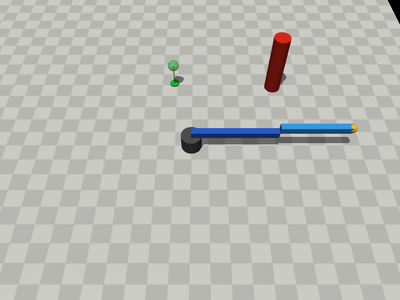
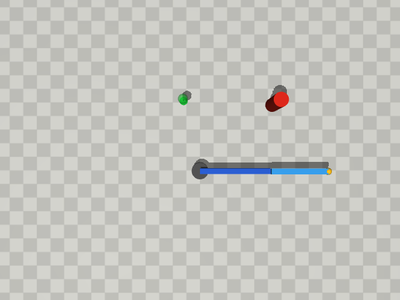

This browser does not support the video tag.


最終誤差 0.0 cm / 接触 False


In [5]:
def ik(x, y, elbow="down"):
    """確認用の逆運動学（解析解）。elbow="down" は肘を右に出す解。"""
    d = (x * x + y * y - L1 ** 2 - L2 ** 2) / (2 * L1 * L2)
    if abs(d) > 1:
        raise ValueError("到達できない目標です")
    q2 = math.acos(d) * (1 if elbow == "down" else -1)
    q1 = math.atan2(y, x) - math.atan2(L2 * math.sin(q2), L1 + L2 * math.cos(q2))
    return ((q1 + math.pi) % (2 * math.pi) - math.pi, q2)

SIM.set_scene((-0.12, 0.51), [{"x": 0.53, "y": 0.48, "r": 0.05}])
media.show_images([SIM.frame("overview"), SIM.frame("top")], titles=["斜めから", "真上から"], height=300)

target = (0.30, 0.60)
r = SIM.execute([ik(*target)], target, [], record=True)
media.show_video(r["frames"], fps=FPS, height=360)
print(f"最終誤差 {r['tip_error_cm']} cm / 接触 {r['contact']}")

## 6. シナリオ

5つのシナリオは、難しさに段階をつけてあります。いずれも、検証に通る解が存在することを確認済みです。座標は根元が原点、+xが正面、+yが左（単位 m）です。

In [6]:
import json


SCENARIOS = {
    # 対照：障害物は経路の外。障害物なしと同じコードで通るはず
    "S1": {"target": (0.30, 0.60), "obstacles": [{"x": 0.20, "y": -0.30, "r": 0.05}],
           "vague": "アームの右側、少し前に細い柱（直径10 cmほど）を置いた。目標とは反対側にある。"},
    # 肘の向きを変えれば避けられる
    "S2": {"target": (0.38, 0.47), "obstacles": [{"x": 0.78, "y": 0.44, "r": 0.05}],
           "vague": "正面やや左、腕を伸ばしきったあたりに細い柱（直径10 cmほど）を置いた。"},
    # 腕を折りたたんでから回す必要がある
    "S3": {"target": (-0.12, 0.51), "obstacles": [{"x": 0.53, "y": 0.48, "r": 0.05}],
           "vague": "左斜め前、根元から70 cmほどの所に細い柱（直径10 cmほど）を置いた。"},
    "S4": {"target": (-0.27, 0.76), "obstacles": [{"x": 0.49, "y": 0.70, "r": 0.05}],
           "vague": "左斜め前の奥、根元から85 cmほどの所に細い柱（直径10 cmほど）を置いた。"},
    "S5": {"target": (0.29, 0.50), "obstacles": [{"x": 0.58, "y": 0.26, "r": 0.05}],
           "vague": "正面やや左、根元から60 cmほどの所に細い柱（直径10 cmほど）を置いた。"},
}

# 障害物なしの基本動作（差分修正の出発点となるコードを作るときに使う）
BASE_TARGET = (0.30, 0.60)

# ビューア（view_run.py）用にシナリオを書き出す
with open(f"{OUT}/scenarios.json", "w", encoding="utf-8") as f:
    json.dump(SCENARIOS, f, ensure_ascii=False, indent=1)

# 確認：まっすぐ動かすと、どのシナリオで検証に落ちるか
for sid, sc in SCENARIOS.items():
    t, obs = sc["target"], sc["obstacles"]
    down, up = verify([ik(*t, "down")], t, obs)[0], verify([ik(*t, "up")], t, obs)[0]
    print(f"{sid}: 肘を右に出す解 {'通る' if down else '不合格'} / 肘を左に出す解 {'通る' if up else '不合格'}")

S1: 肘を右に出す解 通る / 肘を左に出す解 通る
S2: 肘を右に出す解 不合格 / 肘を左に出す解 通る
S3: 肘を右に出す解 不合格 / 肘を左に出す解 不合格
S4: 肘を右に出す解 不合格 / 肘を左に出す解 不合格
S5: 肘を右に出す解 不合格 / 肘を左に出す解 不合格


## 7. プロンプト

全条件で同じシステムプロンプトを使い、ユーザー側の指示文だけを条件によって変えます。プロンプトを変えて試すときは、このセルを編集して再実行してください。

In [7]:

SYSTEM = """あなたは産業用ロボットのプログラマです。2関節の平面ロボットアームの動作計画をPythonで書きます。

## ロボット仕様
- 水平面内で動く2関節アーム。根元は原点 (0, 0) に固定
- 座標系：+x が正面、+y が左。単位はメートル
- リンク長：L1 = 0.5（根元〜肘）、L2 = 0.4（肘〜先端）。リンクの太さは 4 cm
- 関節角 q1, q2 [rad]。q1 はx軸から測った第1リンクの角度、q2 は第1リンクに対する第2リンクの相対角度
- ゼロ姿勢 (0, 0) は両リンクが +x 方向に一直線に伸びた状態。反時計回りが正
- 可動範囲：q1, q2 ともに ±2.98 rad
- 開始姿勢は常に (0, 0)

## 実行のされ方
- あなたが書く関数 plan(target, obstacles) は、関節角の経由点のリスト [(q1, q2), ...] を返す
- 実行系は、開始姿勢から各経由点へ、関節空間で直線補間しながら順に動かす
- 最後の経由点で、先端が target から 1 cm 以内にあること
- 実行前に検証系が、可動範囲・障害物との接触（安全余裕 2 cm）・最終誤差をチェックする

## 引数
- target: (x, y) のタプル
- obstacles: [{"x": float, "y": float, "r": float}, ...]（円柱。r は半径）

## 制約
- import してよいのは math だけ
- 座標や角度を直接書き込まず、引数から計算すること
- 到達できない目標なら ValueError を送出すること
- 出力は ```python のコードブロック1つだけ。説明は # コメントで短く書く（コードの外に説明を書かない）
"""


def task_numeric(sc):
    obs = "\n".join(f"- 中心 ({o['x']}, {o['y']})、半径 {o['r']} m の円柱" for o in sc["obstacles"])
    return (f"作業内容が変わりました。次の位置に障害物を置きました。\n{obs}\n\n"
            f"先端を {sc['target']} へ移動する plan 関数を書いてください。")


def task_vague(sc):
    return (f"作業内容が変わりました。{sc['vague']}\n"
            f"正確な位置はわかりません。想定した障害物の位置と大きさを obstacles の形で "
            f"ASSUMED_OBSTACLES という変数にコードの先頭で定義し、引数の obstacles が空のときはそれを使ってください。\n\n"
            f"先端を {sc['target']} へ移動する plan 関数を書いてください。")


def task_base(target):
    return (f"障害物はありません。先端を指定位置へ移動する plan 関数を書いてください。"
            f"動作確認には target = {target} を使います。")


def wrap_diff(task, base_code):
    return (f"現在、次のコードで運用しています（障害物は考慮していません）。\n\n"
            f"```python\n{base_code}\n```\n\n"
            f"{task}\n既存コードの構造をできるだけ残し、必要な部分だけ修正してください。"
            f"修正後のコード全体を出力してください。")


def feedback(reason):
    return (f"検証で不合格になりました。理由：{reason}\n"
            f"原因を # コメントで簡潔に書いたうえで、修正したコード全体を出力してください。")

## 8. コード生成とサンドボックス

- `call_llm`：会話履歴をClaude APIに送り、返答を受け取る。`mock` に返答のリストを渡すと、APIを使わずにその返答を順に返す（配線確認用）
- `run_plan`：生成コードを別プロセスで実行し、`plan()` が返した経由点を受け取る。importできるのは `math` だけで、10秒で打ち切る

生成コードはロボットを直接動かしません。経由点を返すだけで、ロボットへの指令は検証を通ったあとに実行系が出します。

In [8]:
import json, re, sys, tempfile, time

# 生成コードを実行する小さなプログラム。別プロセスで動かし、組み込み関数を絞る
SANDBOX_CODE = r'''
import json, math, sys, builtins
ALLOWED = ["abs", "min", "max", "range", "len", "enumerate", "zip", "sorted", "sum", "round",
           "float", "int", "str", "list", "tuple", "dict", "set", "frozenset", "bool", "isinstance",
           "any", "all", "map", "filter", "reversed", "next", "iter", "divmod", "pow", "repr",
           "hasattr", "getattr", "setattr", "type", "object", "staticmethod", "classmethod", "property",
           "super", "print", "True", "False", "None", "__build_class__",
           "Exception", "ValueError", "TypeError", "IndexError", "KeyError", "ZeroDivisionError",
           "ArithmeticError", "RuntimeError", "StopIteration", "NotImplementedError"]
def safe_import(name, *args, **kwargs):
    if name != "math":
        raise ImportError(f"import できるのは math だけです: {name}")
    return math
code = open(sys.argv[1], encoding="utf-8").read()
args = json.loads(sys.argv[2])
env_builtins = {k: getattr(builtins, k) for k in ALLOWED if hasattr(builtins, k)}
env_builtins["__import__"] = safe_import
env = {"__builtins__": env_builtins, "__name__": "generated", "math": math}
try:
    exec(code, env)
    result = env["plan"](tuple(args["target"]), args["obstacles"])
    out = {"ok": True, "waypoints": [list(map(float, p)) for p in result]}
except Exception as e:
    out = {"ok": False, "error": f"{type(e).__name__}: {e}"}
assumed = env.get("ASSUMED_OBSTACLES")
if isinstance(assumed, (list, tuple)):
    try:
        out["assumed"] = [{"x": float(o["x"]), "y": float(o["y"]), "r": float(o["r"])} for o in assumed]
    except Exception:
        pass
print(json.dumps(out, ensure_ascii=False))
'''
SANDBOX = os.path.abspath("sandbox_runner.py")
with open(SANDBOX, "w", encoding="utf-8") as f:
    f.write(SANDBOX_CODE)


MAX_TOKENS = 8000          # 1回の返答の上限。途切れたら、その旨をLLMに伝えて書き直させる
LAST_STOP_REASON = None
RAW_LOG = f"{OUT}/raw_responses.jsonl"   # 返答の原文、終了理由、トークン数を残す（原因調査と費用の確認用）


def call_llm(messages, mock=None):
    """会話履歴を送り、(返答テキスト, 秒数) を返す。mock があればAPIを呼ばない。"""
    global LAST_STOP_REASON
    if mock is not None:
        LAST_STOP_REASON = None
        n = sum(1 for m in messages if m["role"] == "assistant")
        return mock[min(n, len(mock) - 1)], 0.0
    import anthropic
    client = anthropic.Anthropic()
    t0 = time.time()
    res = client.messages.create(model=MODEL, max_tokens=MAX_TOKENS, system=SYSTEM, messages=messages)
    text = "".join(b.text for b in res.content if b.type == "text")
    LAST_STOP_REASON = res.stop_reason
    with open(RAW_LOG, "a", encoding="utf-8") as f:
        f.write(json.dumps({"time": time.strftime("%Y-%m-%dT%H:%M:%S"), "model": MODEL,
                            "stop_reason": res.stop_reason,
                            "input_tokens": res.usage.input_tokens,
                            "output_tokens": res.usage.output_tokens,
                            "text": text}, ensure_ascii=False) + "\n")
    return text, time.time() - t0


# ```python / ```py / ``` のどれでも拾う。閉じの ``` がない（途中で切れた）場合は最後まで
FENCE = re.compile(r"```[ \t]*([A-Za-z0-9_+-]*)[^\n]*\n(.*?)(?:```|\Z)", re.S)


def _fail(msg):
    """取り出しに失敗したとき、その理由をエラーとして返すコード（理由がそのままLLMへの修正依頼になる）。"""
    return f"raise ValueError({msg!r})"


def extract_code(text, stop_reason=None):
    """返答から、def plan を含むPythonのコードブロックを取り出す。"""
    stop_reason = stop_reason or LAST_STOP_REASON
    if stop_reason == "max_tokens":
        return _fail("返答が長すぎて途中で切れました。コメントや説明を減らし、"
                     "def plan を含む完全なコードを ```python のブロック1つで出力してください")
    blocks = [(lang.lower(), body) for lang, body in FENCE.findall(text)]
    py = [body for lang, body in blocks if lang in ("python", "py", "python3", "")]
    with_plan = [b for b in py if re.search(r"^def plan\s*\(", b, re.M)]
    if with_plan:
        return max(with_plan, key=len).strip()           # 複数あれば一番長いもの（完全版）を使う
    if not blocks and re.search(r"^def plan\s*\(", text, re.M):
        return text.strip()                             # ブロックなしでコードだけ返した場合
    if py:
        return _fail("コードブロックに def plan(target, obstacles) がありません。"
                     "plan 関数を含む完全なコードを ```python のブロック1つで出力してください")
    return _fail("返答に ```python のコードブロックがありません。"
                 "plan 関数を含む完全なコードを ```python のブロック1つで出力してください")


def run_plan(code, target, obstacles, timeout=10):
    """生成コードの plan() をサンドボックスで実行し、経由点かエラーを返す。"""
    with tempfile.NamedTemporaryFile("w", suffix=".py", delete=False, encoding="utf-8") as f:
        f.write(code)
        path = f.name
    try:
        out = subprocess.run(
            [sys.executable, "-I", SANDBOX, path,
             json.dumps({"target": list(target), "obstacles": obstacles})],
            capture_output=True, text=True, timeout=timeout)
        return json.loads(out.stdout.strip().splitlines()[-1])
    except subprocess.TimeoutExpired:
        return {"ok": False, "error": f"{timeout}秒以内に終わりませんでした"}
    except Exception as e:
        return {"ok": False, "error": f"実行に失敗しました: {e}"}
    finally:
        os.unlink(path)

print("準備できました")

準備できました


## 9. 実験ランナー

1回の試行は次の流れです。

1. 条件に合わせて指示文を作る（ゼロから生成か差分修正か、数値の指示かあいまいな指示か）
2. LLMにコードを書かせ、サンドボックスで `plan()` を実行して経由点を得る
3. 検証関数で検査する。不合格なら理由を会話に足して書き直させる（最大3回）
4. 各回の計画をMuJoCoでも動かし、物理的に接触したかと最終誤差を記録する（描画なしなので数秒で終わる）

あいまいな指示では、`plan()` に障害物の座標を渡しません。検証とシミュレーションは真の位置で行います。結果は `results.jsonl` に1行1試行で追記し、生成コードは `runs/` に保存します。一度記録した試行は飛ばすので、途中で切れても同じセルを再実行すれば続きから回ります。

In [9]:
import datetime

MAX_ATTEMPTS = 3


def done_tags():
    if not os.path.exists(RESULTS):
        return set()
    return {json.loads(l)["tag"] for l in open(RESULTS, encoding="utf-8") if l.strip()}


def make_base(mock=None):
    """障害物なしの基本コードを作り、base_plan.py に保存する（差分修正の出発点）。"""
    text, _ = call_llm([{"role": "user", "content": task_base(BASE_TARGET)}], mock)
    code = extract_code(text)
    res = run_plan(code, BASE_TARGET, [])
    ok, reason = verify(res["waypoints"], BASE_TARGET, []) if res["ok"] else (False, res["error"])
    with open(BASE_FILE, "w", encoding="utf-8") as f:
        f.write(code)
    print(f"base_plan.py を保存しました（検証: {'合格' if ok else '不合格 - ' + reason}）\n")
    print(code)
    return code


def run_one(sid, mode, instr, trial, mock=None, log=True, verbose=True):
    sc = SCENARIOS[sid]
    task = task_numeric(sc) if instr == "numeric" else task_vague(sc)
    if mode == "diff":
        task = wrap_diff(task, open(BASE_FILE, encoding="utf-8").read())
    obs_for_code = sc["obstacles"] if instr == "numeric" else []   # あいまい指示では座標を渡さない

    tag = f"{sid}_{mode}_{instr}_t{trial}"
    messages = [{"role": "user", "content": task}]
    rec = {"tag": tag, "scenario": sid, "mode": mode, "instr": instr, "trial": trial,
           "model": "mock" if mock is not None else MODEL, "attempts": [], "passed": False}

    for k in range(1, MAX_ATTEMPTS + 1):
        text, sec = call_llm(messages, mock)
        code = extract_code(text)
        code_path = f"{OUT}/runs/{tag}_a{k}.py"
        with open(code_path, "w", encoding="utf-8") as f:
            f.write(code)
        res = run_plan(code, sc["target"], obs_for_code)
        att = {"n": k, "seconds": round(sec, 1), "lines": len(code.splitlines()), "code": code_path,
               "waypoints": res.get("waypoints"), "assumed": res.get("assumed")}
        if res["ok"]:
            ok, reason = verify(res["waypoints"], sc["target"], sc["obstacles"])
            sim = SIM.execute(res["waypoints"], sc["target"], sc["obstacles"])   # 描画なし
            att.update(sim_contact=sim["contact"], sim_tip_error_cm=sim["tip_error_cm"])
        else:
            ok, reason = False, f"コードの実行エラー: {res['error']}"
        att.update(passed=ok, reason=reason)
        rec["attempts"].append(att)
        if verbose:
            extra = f"（シミュレーション：接触{'あり' if att.get('sim_contact') else 'なし'}）" if res["ok"] else ""
            print(f"[{tag}] 試行{k}: {'合格' if ok else '不合格 - ' + reason}{extra}")
        if ok:
            rec["passed"] = True
            break
        messages += [{"role": "assistant", "content": text},
                     {"role": "user", "content": feedback(reason)}]

    rec["time"] = datetime.datetime.now().isoformat(timespec="seconds")
    if log:
        with open(RESULTS, "a", encoding="utf-8") as f:
            f.write(json.dumps(rec, ensure_ascii=False) + "\n")
    return rec


def run_all(trials=3, modes=("scratch", "diff"), instrs=("numeric", "vague"), mock=None):
    skip = done_tags()
    todo = [(s, m, i, t) for s in SCENARIOS for m in modes for i in instrs for t in range(1, trials + 1)
            if f"{s}_{m}_{i}_t{t}" not in skip]
    print(f"残り {len(todo)} 試行（記録済み {len(skip)}）")
    for j, (s, m, i, t) in enumerate(todo, 1):
        try:
            r = run_one(s, m, i, t, mock=mock, verbose=False)
            n = len(r["attempts"])
            print(f"{j}/{len(todo)} {r['tag']}: {'合格' if r['passed'] else '不合格'}（{n}回）")
        except Exception as e:      # APIの一時的なエラーなど。次の試行へ進み、再実行で拾う
            print(f"{j}/{len(todo)} {s}_{m}_{i}_t{t}: エラーで中断 - {type(e).__name__}: {e}")
            time.sleep(5)

print("準備できました")

準備できました


## 10. 配線の確認（ダミーLLM）

APIを使わずに、生成→実行→検証→書き直し→シミュレーションの流れがつながっているかを確かめます。ダミーの返答を2つ用意しました。

- 1つ目：障害物を無視して、まっすぐ目標へ向かうコード（S3では接触するはず）
- 2つ目：腕を折りたたんでから回すコード（検証に通るはず）

「試行1: 不合格（接触）」「試行2: 合格」と表示され、2本の動画で、1本目は障害物が黄色に変わり、2本目は避けて目標に届けば成功です。この確認は `results.jsonl` に記録しません。

In [10]:
MOCK_DIRECT = '''```python
import math

def plan(target, obstacles):
    # 障害物を考えず、肘を右に出す解でまっすぐ向かう
    L1, L2 = 0.5, 0.4
    x, y = target
    d = (x * x + y * y - L1 ** 2 - L2 ** 2) / (2 * L1 * L2)
    if abs(d) > 1:
        raise ValueError("到達不能")
    q2 = math.acos(d)
    q1 = math.atan2(y, x) - math.atan2(L2 * math.sin(q2), L1 + L2 * math.cos(q2))
    return [(q1, q2)]
```'''

MOCK_FOLD = '''```python
import math

L1, L2 = 0.5, 0.4
CLEAR = 0.02 + 0.02 + 0.005      # リンクの半幅 + 安全余裕 + 念のための上乗せ

def ik(x, y, sign):
    d = (x * x + y * y - L1 ** 2 - L2 ** 2) / (2 * L1 * L2)
    if abs(d) > 1:
        raise ValueError("到達不能")
    q2 = sign * math.acos(d)
    q1 = math.atan2(y, x) - math.atan2(L2 * math.sin(q2), L1 + L2 * math.cos(q2))
    q1 = (q1 + math.pi) % (2 * math.pi) - math.pi
    return q1, q2

def seg_dist(ax, ay, bx, by, px, py):
    dx, dy = bx - ax, by - ay
    t = max(0.0, min(1.0, ((px - ax) * dx + (py - ay) * dy) / (dx * dx + dy * dy)))
    return math.hypot(px - ax - t * dx, py - ay - t * dy)

def hits(q, obstacles):
    ex, ey = L1 * math.cos(q[0]), L1 * math.sin(q[0])
    tx, ty = ex + L2 * math.cos(q[0] + q[1]), ey + L2 * math.sin(q[0] + q[1])
    for o in obstacles:
        c = o["r"] + CLEAR
        if seg_dist(0, 0, ex, ey, o["x"], o["y"]) < c or seg_dist(ex, ey, tx, ty, o["x"], o["y"]) < c:
            return True
    return False

def path_ok(waypoints, obstacles):
    prev = (0.0, 0.0)
    for wp in waypoints:
        n = max(1, int(max(abs(wp[0] - prev[0]), abs(wp[1] - prev[1])) / 0.005))
        for i in range(n + 1):
            q = (prev[0] + (wp[0] - prev[0]) * i / n, prev[1] + (wp[1] - prev[1]) * i / n)
            if hits(q, obstacles):
                return False
        prev = wp
    return True

def plan(target, obstacles):
    # まず直行を試し、だめなら「前腕を折りたたむ→根元を回す→伸ばす」を試す
    for sign in (1, -1):
        q = ik(*target, sign)
        if path_ok([q], obstacles):
            return [q]
    for sign in (1, -1):
        q = ik(*target, sign)
        for f in (1.5, 1.75, 2.0, 2.25, 2.5):
            fold = sign * f
            wps = [(0.0, fold), (q[0], fold), q]
            if path_ok(wps, obstacles):
                return wps
    raise ValueError("障害物を避ける経路が見つかりません")
```'''

rec = run_one("S3", "scratch", "numeric", trial=0, mock=[MOCK_DIRECT, MOCK_FOLD], log=False)
sc = SCENARIOS["S3"]
for att in rec["attempts"]:
    r = SIM.execute(att["waypoints"], sc["target"], sc["obstacles"], record=True)
    print(f"試行{att['n']}：検証 {'合格' if att['passed'] else '不合格'} / シミュレーションで接触 {r['contact']}")
    media.show_video(r["frames"], fps=FPS, height=300)

[S3_scratch_numeric_t0] 試行1: 不合格 - 経路の途中で障害物に接触します（q1=0.37, q2=0.70, 先端=(0.66, 0.53)）（シミュレーション：接触あり）
[S3_scratch_numeric_t0] 試行2: 合格（シミュレーション：接触なし）
試行1：検証 不合格 / シミュレーションで接触 True


This browser does not support the video tag.


試行2：検証 合格 / シミュレーションで接触 False


This browser does not support the video tag.


## 11. 基本コードの作成（ここからAPIを使います）

障害物なしで目標へ動かす基本コードをLLMに書かせ、`base_plan.py` として保存します。差分修正の条件では、これを「現場で運用中の既存コード」として渡します。

表示されたコードを読み、逆運動学が正しく書けているか（`atan2` の引数の順序、肘の向き、到達できない目標の扱い）を確認してください。以後は書き換えません。作り直したいときだけ、もう一度実行してください。

In [11]:
if os.path.exists(BASE_FILE):
    print("base_plan.py はすでにあります。作り直す場合は REMAKE = True にしてください\n")
    print(open(BASE_FILE, encoding="utf-8").read())
REMAKE = False
if REMAKE or not os.path.exists(BASE_FILE):
    make_base()

base_plan.py はすでにあります。作り直す場合は REMAKE = True にしてください

import math

L1 = 0.5            # 根元〜肘 [m]
L2 = 0.4            # 肘〜先端 [m]
LINK_HALF_WIDTH = 0.02   # リンク太さ 4cm の半分
SAFETY_MARGIN = 0.02     # 安全余裕 2cm
JOINT_LIMIT = 2.98       # 可動範囲 ±2.98 rad
TOLERANCE = 0.01         # 最終誤差の許容値 1cm（IK誤差はこれよりはるかに小さい）


def _wrap(a):
    """角度を (-pi, pi] に正規化する。"""
    while a > math.pi:
        a -= 2.0 * math.pi
    while a <= -math.pi:
        a += 2.0 * math.pi
    return a


def _fk(q1, q2):
    """順運動学: 肘と先端の座標を返す。"""
    ex = L1 * math.cos(q1)
    ey = L1 * math.sin(q1)
    tx = ex + L2 * math.cos(q1 + q2)
    ty = ey + L2 * math.sin(q1 + q2)
    return (ex, ey), (tx, ty)


def _seg_point_dist(p, a, b):
    """線分 ab と点 p の最短距離。"""
    abx, aby = b[0] - a[0], b[1] - a[1]
    apx, apy = p[0] - a[0], p[1] - a[1]
    len2 = abx * abx + aby * aby
    t = 0.0 if len2 == 0 else max(0.0, min(1.0, (apx * abx + apy * aby) / len2))
    cx, cy = a[0] + t * abx, a[1] + t * aby
    return math.hypot(p[0] - 

## 12. 実験の実行

4条件（ゼロから生成／差分修正 × 数値の指示／あいまいな指示）× 5シナリオ × 3回 ＝ 60試行です。描画しないので、時間はほぼAPIの応答待ちで、全体で30〜60分を見込みます。

途中で止めたり、Notebookを閉じたりしても、続きから再開できます。このセルを選んだ状態でメニューの「Run」→「Run All Above Selected Cell」で準備をやり直し、このセルを再実行してください。記録済みの試行は飛ばして続きから回ります。実験中にMacがスリープしないよう、手順書の手順1の設定をしておいてください。

まず1試行だけ回して様子を見たいときは、下の `run_one(...)` の行の先頭の `#` を消し、`run_all(...)` の行の先頭に `#` を付けて実行してください。

In [13]:
# 1試行だけ試す場合（結果は記録される）
# run_one("S3", "scratch", "numeric", trial=1)
# run_one("S2", "scratch", "numeric", trial=1)
run_all(trials=3)

残り 59 試行（記録済み 1）
1/59 S1_scratch_numeric_t1: 合格（1回）
2/59 S1_scratch_numeric_t2: 合格（1回）
3/59 S1_scratch_numeric_t3: 合格（1回）
4/59 S1_scratch_vague_t1: 合格（1回）
5/59 S1_scratch_vague_t2: 合格（1回）
6/59 S1_scratch_vague_t3: 合格（1回）
7/59 S1_diff_numeric_t1: 合格（1回）
8/59 S1_diff_numeric_t2: 合格（1回）
9/59 S1_diff_numeric_t3: 合格（1回）
10/59 S1_diff_vague_t1: 合格（1回）
11/59 S1_diff_vague_t2: 合格（1回）
12/59 S1_diff_vague_t3: 合格（1回）
13/59 S2_scratch_numeric_t2: 合格（1回）
14/59 S2_scratch_numeric_t3: 合格（1回）
15/59 S2_scratch_vague_t1: 合格（1回）
16/59 S2_scratch_vague_t2: 合格（1回）
17/59 S2_scratch_vague_t3: 合格（1回）
18/59 S2_diff_numeric_t1: 合格（1回）
19/59 S2_diff_numeric_t2: 合格（1回）
20/59 S2_diff_numeric_t3: 合格（2回）
21/59 S2_diff_vague_t1: 合格（1回）
22/59 S2_diff_vague_t2: 合格（2回）
23/59 S2_diff_vague_t3: 合格（1回）
24/59 S3_scratch_numeric_t1: 合格（2回）
25/59 S3_scratch_numeric_t2: 合格（1回）
26/59 S3_scratch_numeric_t3: 合格（1回）
27/59 S3_scratch_vague_t1: 合格（1回）
28/59 S3_scratch_vague_t2: 合格（1回）
29/59 S3_scratch_vague_t3: 合格（1回）
30/59 S3_diff_

## 13. 集計

条件ごとの成功率、1回目で合格した割合、平均試行回数と、不合格の理由の内訳を出します。動画用に回した試行（trialが0または9以上）は除きます。

「検証で不合格・シミュレーションでは接触なし」は、安全余裕（2 cm）の内側には入ったが、物理的には触れていない計画です。検証が保守的に止めた件数として読んでください。

In [14]:
import collections
import pandas as pd

rows = [json.loads(l) for l in open(RESULTS, encoding="utf-8") if l.strip()]
rows = [r for r in rows if 1 <= r["trial"] <= 8]

def kind(a):
    if a["passed"]:
        return "合格"
    if "実行エラー" in a["reason"] or "秒以内" in a["reason"]:
        return "コードの実行エラー"
    if "接触" in a["reason"]:
        return "障害物に接触"
    if "可動範囲" in a["reason"]:
        return "可動範囲の超過"
    if "誤差" in a["reason"]:
        return "目標に届かない"
    return "その他"

MODE_JA = {"scratch": "ゼロから生成", "diff": "差分修正"}
INSTR_JA = {"numeric": "数値の指示", "vague": "あいまいな指示"}
summary = []
groups = collections.defaultdict(list)
for r in rows:
    groups[(r["mode"], r["instr"])].append(r)
for (mode, instr), g in sorted(groups.items(), key=lambda kv: (kv[0][0] != "scratch", kv[0][1] != "numeric")):
    ok = [r for r in g if r["passed"]]
    summary.append({
        "生成方式": MODE_JA[mode], "指示": INSTR_JA[instr], "試行数": len(g),
        "成功率": f"{len(ok) / len(g):.0%}",
        "1回目で合格": f"{sum(r['attempts'][0]['passed'] for r in g) / len(g):.0%}",
        "平均試行回数（成功のみ）": round(sum(len(r["attempts"]) for r in ok) / len(ok), 2) if ok else None,
        "平均コード行数": round(sum(a["lines"] for r in g for a in r["attempts"]) / sum(len(r["attempts"]) for r in g), 1),
    })
summary_df = pd.DataFrame(summary)
display(summary_df)

# シナリオ×条件ごとの成功数（例：3/3）
cells = collections.defaultdict(lambda: [0, 0])
for r in rows:
    c = cells[(r["scenario"], f"{MODE_JA[r['mode']]}・{INSTR_JA[r['instr']]}")]
    c[0] += r["passed"]
    c[1] += 1
by_scn = pd.Series({k: f"{v[0]}/{v[1]}" for k, v in cells.items()}).unstack()
display(by_scn)

kinds = collections.Counter(kind(a) for r in rows for a in r["attempts"] if not a["passed"])
conservative = sum(1 for r in rows for a in r["attempts"]
                   if not a["passed"] and "接触" in a["reason"] and a.get("sim_contact") is False)
print("不合格の内訳（書き直しを含む全試行）")
for k, v in kinds.most_common():
    print(f"  {k}: {v}")
print(f"  うち「検証で不合格・シミュレーションでは接触なし」: {conservative}")

summary_df.to_csv(f"{OUT}/results_summary.csv", index=False, encoding="utf-8-sig")

,生成方式,指示,試行数,成功率,1回目で合格,平均試行回数（成功のみ）,平均コード行数
0,ゼロから生成,数値の指示,15,100%,93%,1.07,147.3
1,ゼロから生成,あいまいな指示,15,100%,87%,1.13,130.4
2,差分修正,数値の指示,15,100%,40%,1.60,88.1
3,差分修正,あいまいな指示,15,100%,33%,1.80,68.5


,ゼロから生成・あいまいな指示,ゼロから生成・数値の指示,差分修正・あいまいな指示,差分修正・数値の指示
S1,3/3,3/3,3/3,3/3
S2,3/3,3/3,3/3,3/3
S3,3/3,3/3,3/3,3/3
S4,3/3,3/3,3/3,3/3
S5,3/3,3/3,3/3,3/3


不合格の内訳（書き直しを含む全試行）
  コードの実行エラー: 24
  うち「検証で不合格・シミュレーションでは接触なし」: 0


In [15]:
logs = [json.loads(l) for l in open(RAW_LOG, encoding="utf-8")]
i = sum(x["input_tokens"] for x in logs); o = sum(x["output_tokens"] for x in logs)
print(f"{len(logs)}回の呼び出し / 入力 {i:,} / 出力 {o:,} トークン / 約 ${i / 1e6 * 2 + o / 1e6 * 10:.2f}")

84回の呼び出し / 入力 187,386 / 出力 490,522 トークン / 約 $5.28


## 14. 動画の作成

実験の記録から代表的な試行を選び、1本の動画にまとめます。LLMを呼び直す必要はなく、記録された経由点と生成コードから描画します。

構成は、タイトル → 基本動作 → 障害物の追加（指示文、生成コード、検証、実行）→ あいまいな指示 → 集計結果、です。画面の左がシミュレーション、右がその回の生成コードです。

- `EXAMPLES` に `(シナリオ, 方式, 指示, trial)` を書くと、その試行を使う。空なら、S2〜S5の数値の指示から「1回目に接触で不合格→書き直して合格」の試行を優先して自動で選ぶ
- `N_EXAMPLES` で、障害物の例をいくつ入れるかを決める。2つで1分〜1分半、3つで1分半〜2分が目安（書き直しの回数で変わる）
- 描画にかかる時間は1分前後

動画は `videos/story.mp4` に保存され、下に再生画面が出ます。

In [19]:
from PIL import Image, ImageDraw
from IPython.display import Video, display
import numpy as np

EXAMPLES = []          # 例: [("S3", "scratch", "numeric", 2), ("S5", "diff", "numeric", 1)]
N_EXAMPLES = 2
VAGUE_EXAMPLE = None   # 例: ("S4", "scratch", "vague", 1)
STORY = f"{OUT}/videos/story.mp4"
FINDINGS = [
    "84回の生成で、障害物にぶつかる計画は0件。LLMは自分で衝突判定と経路探索を書き、1回で解いた。",
    "検証→書き直しのループが効いたのは、出力の途中切れなど形式の誤りだけだった。",
    "差分修正では1回目の失敗21件がすべて途中切れ。既存コードを渡すと推論が長くなるとみられる。",
    "限界：シナリオが易しすぎた。次は障害物を増やし、幾何の誤りが出る条件で試したい。",
]

SIM_W, SIM_H, PANEL_W = 640, 480, 560
VW, VH = SIM_W + PANEL_W, SIM_H
INK, QUIET, BG, PANEL_BG = (235, 235, 235), (160, 165, 170), (24, 26, 30), (32, 35, 40)
GOOD, BAD, ACCENT = (70, 190, 110), (230, 80, 70), (90, 160, 240)


def font(size, mono=False):
    return ImageFont.truetype(FONT_PATH, size, index=FONT_MONO if mono else FONT_SANS)


def wrap(text, f, width):
    lines, line = [], ""
    for ch in text:
        if ch == "\n" or f.getlength(line + ch) > width:
            lines.append(line)
            line = "" if ch == "\n" else ch
        else:
            line += ch
    return lines + [line]


def card(title, body=(), sec=3.0):
    """文字だけの場面（タイトル、区切り、まとめ）。"""
    img = Image.new("RGB", (VW, VH), BG)
    d = ImageDraw.Draw(img)
    ft, fb = font(34), font(20)
    y = 150 if body else 210
    for line in wrap(title, ft, VW - 160):
        d.text((80, y), line, font=ft, fill=INK)
        y += 48
    y += 16
    for para in body:
        for line in wrap(para, fb, VW - 160):
            d.text((80, y), line, font=fb, fill=QUIET)
            y += 32
    frame = np.asarray(img)
    return [frame] * int(sec * FPS)


def code_panel(code, header):
    img = Image.new("RGB", (PANEL_W, VH), PANEL_BG)
    d = ImageDraw.Draw(img)
    d.text((16, 12), header, font=font(15), fill=QUIET)
    lines = code.splitlines()
    # 全体が入らないときは、plan 関数の先頭から見せる
    start = 0 if len(lines) <= 26 else next((i for i, l in enumerate(lines) if l.startswith("def plan")), 0)
    fm = font(12, mono=True)
    y = 44
    for l in lines[start:start + 26]:
        while fm.getlength(l) > PANEL_W - 32 and len(l) > 1:
            l = l[:-1]
        d.text((16, y), l, font=fm, fill=INK)
        y += 16
    if start + 26 < len(lines):
        d.text((16, y), "…", font=fm, fill=QUIET)
    return np.asarray(img)


def compose(sim_frame, panel, label, banner=None, color=GOOD):
    img = Image.fromarray(np.concatenate([sim_frame, panel], axis=1))
    d = ImageDraw.Draw(img)
    fl = font(16)
    w = int(fl.getlength(label)) + 24
    d.rectangle([12, 12, 12 + w, 44], fill=(0, 0, 0))
    d.text((24, 17), label, font=fl, fill=INK)
    if banner:
        fb = font(22)
        lines = wrap(banner, fb, SIM_W - 48)
        h = 20 + 32 * len(lines)
        d.rectangle([0, SIM_H - h, SIM_W, SIM_H], fill=color)
        for i, line in enumerate(lines):
            d.text((24, SIM_H - h + 10 + 32 * i), line, font=fb, fill=(255, 255, 255))
    return np.asarray(img)


def attempt_clip(rec, att, label):
    """1回分の生成コードと、その計画をシミュレーションで動かした様子。"""
    sc = SCENARIOS[rec["scenario"]]
    code = open(att["code"], encoding="utf-8").read()
    panel = code_panel(code, f"生成コード（試行{att['n']}、{att['lines']}行）")
    if att["passed"]:
        verdict, color = "検証：合格 → 実行", GOOD
    else:
        verdict, color = "検証：不合格 － " + att["reason"].split("（")[0], BAD
    if not att.get("waypoints"):
        SIM.set_scene(sc["target"], sc["obstacles"], att.get("assumed"))
        f = SIM.frame()
        return [compose(f, panel, label)] * FPS + [compose(f, panel, label, verdict, color)] * int(2.5 * FPS)
    r = SIM.execute(att["waypoints"], sc["target"], sc["obstacles"], record=True, assumed=att.get("assumed"))
    if not att["passed"]:
        verdict += "（実行すると：" + ("接触" if r["contact"] else "物理的には接触なし") + "）"
    frames = [compose(f, panel, label) for f in r["frames"]]
    return frames + [compose(r["frames"][-1], panel, label, verdict, color)] * int(2.5 * FPS)


def find_examples(rows, n):
    """障害物が効くシナリオ（S2〜S5）から、見せたい順に選ぶ。
    1. 1回目に接触で不合格 → 書き直して合格  2. 1回目に不合格 → 合格  3. 合格"""
    def first_fail(r, word=""):
        a = r["attempts"][0]
        return not a["passed"] and word in a["reason"]
    prefs = [lambda r: first_fail(r, "接触") and r["passed"],
             lambda r: first_fail(r) and r["passed"],
             lambda r: r["passed"]]
    picked, used = [], set()
    for pref in prefs:
        for r in rows:
            if (len(picked) < n and r["scenario"] != "S1" and r["instr"] == "numeric"
                    and r["scenario"] not in used and pref(r)):
                picked.append(r)
                used.add(r["scenario"])
    return picked


def find_vague(rows):
    for r in rows:
        if r["instr"] == "vague" and r["scenario"] in ("S3", "S4", "S5") and any(a.get("assumed") for a in r["attempts"]):
            return r
    return None


def get_rec(key):
    tag = "{}_{}_{}_t{}".format(*key)
    return next(r for r in all_rows if r["tag"] == tag)


def instruction_text(rec):
    sc = SCENARIOS[rec["scenario"]]
    if rec["instr"] == "numeric":
        o = sc["obstacles"][0]
        return f"指示：中心 ({o['x']}, {o['y']})、半径 {o['r']} m の円柱を置いた。先端を {sc['target']} へ移動せよ。"
    return f"指示：{sc['vague']} 先端を {sc['target']} へ移動せよ。"


all_rows = [json.loads(l) for l in open(RESULTS, encoding="utf-8") if l.strip()]
exp_rows = [r for r in all_rows if 1 <= r["trial"] <= 8]
examples = [get_rec(k) for k in EXAMPLES] if EXAMPLES else find_examples(exp_rows, N_EXAMPLES)
vague = get_rec(VAGUE_EXAMPLE) if VAGUE_EXAMPLE else find_vague(exp_rows)
MODE_LABEL = {"scratch": "ゼロから生成", "diff": "差分修正"}
INSTR_LABEL = {"numeric": "数値の指示", "vague": "あいまいな指示"}

with media.VideoWriter(STORY, shape=(VH, VW), fps=FPS) as w:
    def put(frames):
        for f in frames:
            w.add_image(f)

    put(card("LLMをロボットのプログラマとして使う",
             ["作業内容の変化を人間が伝え、LLMが制御コードを書く。",
              "コードは実行前に検証し、通ったものだけをロボット（シミュレーション）で動かす。"], 4))

    # 基本動作
    base_code = open(BASE_FILE, encoding="utf-8").read()
    res = run_plan(base_code, BASE_TARGET, [])
    put(card("基本動作：障害物なし", ["LLMが書いた基本コードで、先端を緑の目印へ動かす。"], 2.5))
    if res["ok"]:
        r = SIM.execute(res["waypoints"], BASE_TARGET, [], record=True)
        panel = code_panel(base_code, "基本コード（base_plan.py）")
        put(compose(f, panel, "基本動作") for f in r["frames"])

    # 障害物の追加
    for k, rec in enumerate(examples, 1):
        put(card(f"作業の変化 {k}：障害物を追加（{rec['scenario']}）",
                 [instruction_text(rec), f"生成方式：{MODE_LABEL[rec['mode']]}"], 4))
        for att in rec["attempts"]:
            put(attempt_clip(rec, att, f"{rec['scenario']}・{MODE_LABEL[rec['mode']]}・試行{att['n']}/{MAX_ATTEMPTS}"))

    # あいまいな指示
    if vague:
        att = next(a for a in reversed(vague["attempts"]) if a.get("assumed"))
        a0, o0 = att["assumed"][0], SCENARIOS[vague["scenario"]]["obstacles"][0]
        gap = math.hypot(a0["x"] - o0["x"], a0["y"] - o0["y"]) * 100
        put(card("あいまいな指示", [instruction_text(vague),
                 f"LLMが想定した位置は ({a0['x']:.2f}, {a0['y']:.2f})、半径 {a0['r']:.2f} m。"
                 f"実際の位置とのずれは {gap:.0f} cm。半透明の円柱が想定、赤い円柱が実際の位置。"], 5))
        put(attempt_clip(vague, att, f"{vague['scenario']}・あいまいな指示・試行{att['n']}"))

    # まとめ
    if "summary_df" in globals():
        body = [f"{r['生成方式']}・{r['指示']}：成功率 {r['成功率']}、1回目で合格 {r['1回目で合格']}"
                f"（{r['試行数']}試行）" for _, r in summary_df.iterrows()]
        put(card("結果", body, 6))
    put(card("わかったこと・限界", FINDINGS, 5))

print("保存しました:", STORY)
display(Video(STORY, embed=True, width=900))

保存しました: /Users/YoshiGoto/llm_arm/videos/story.mp4


## 付録：生成コードを読む

手順書の「段階2：観察しながらコードを読む」で使います。`TAG` に試行の名前（例：`S3_scratch_numeric_t1`）を入れて実行すると、各回のコードと検証の結果を順に表示します。

同じ試行の動きを3Dビューアで見るには、ターミナルで `mjpython view_run.py S3_scratch_numeric_t1 1`（最後の数字は試行の回）を実行します。

In [16]:
TAG = "S4_diff_numeric_t1"

rec = next((json.loads(l) for l in open(RESULTS, encoding="utf-8") if json.loads(l)["tag"] == TAG), None)
if rec is None:
    print("見つかりません。記録済みの試行:", sorted(done_tags())[:10], "…")
else:
    for a in rec["attempts"]:
        print(f"===== 試行{a['n']}：{'合格' if a['passed'] else '不合格 - ' + a['reason']}"
              f"（{a['lines']}行、{a['seconds']}秒）")
        if a.get("assumed"):
            print("LLMが想定した障害物:", a["assumed"], "/ 実際:", SCENARIOS[rec["scenario"]]["obstacles"])
        print(open(a["code"], encoding="utf-8").read(), "\n")

===== 試行1：不合格 - コードの実行エラー: ValueError: 返答が長すぎて途中で切れました。コメントや説明を減らし、def plan を含む完全なコードを ```python のブロック1つで出力してください（1行、63.6秒）
raise ValueError('返答が長すぎて途中で切れました。コメントや説明を減らし、def plan を含む完全なコードを ```python のブロック1つで出力してください') 

===== 試行2：合格（158行、32.0秒）
import math

L1 = 0.5            # 根元〜肘 [m]
L2 = 0.4            # 肘〜先端 [m]
LINK_HALF_WIDTH = 0.02   # リンク太さの半分
SAFETY_MARGIN = 0.02     # 安全余裕 2cm
JOINT_LIMIT = 2.98       # 可動範囲 ±2.98 rad
TOLERANCE = 0.01         # 最終誤差の許容値
PLAN_EXTRA = 0.005       # 計画時の追加余裕（サンプリング取りこぼし対策）
EDGE_STEP = 0.005        # 干渉検査の関節角刻み [rad]
GRID_N = 30              # 関節空間グリッド（片側分割数）

# 前回は説明が長すぎて出力が途中で切れた。
# 今回は直線経路が障害物に当たるため、関節空間グリッドBFSで迂回経路を探索する。


def _wrap(a):
    while a > math.pi:
        a -= 2.0 * math.pi
    while a <= -math.pi:
        a += 2.0 * math.pi
    return a


def _fk(q1, q2):
    ex = L1 * math.cos(q1)
    ey = L1 * math.sin(q1)
    tx = ex + L2 * math.cos(q1 + q2)
    ty = ey + L2 * math.sin(q1 + q2)
    return (ex, ey), (tx, ty)


def _seg_point

In [17]:
import collections

# 1) 不合格の理由を、条件ごとに分類する
c = collections.Counter()
for r in (json.loads(l) for l in open(RESULTS, encoding="utf-8") if l.strip()):
    for a in r["attempts"]:
        if not a["passed"]:
            kind = ("途中で切れた" if "途中で切れ" in a["reason"]
                    else "接触" if "接触" in a["reason"] else a["reason"][:40])
            c[(MODE_JA.get(r["mode"], r["mode"]), INSTR_JA.get(r["instr"], r["instr"]), kind)] += 1
print("■ 不合格の内訳（方式・指示・理由：件数）")
for k, v in sorted(c.items()):
    print("  ", " / ".join(k), ":", v)

# 2) 途中で切れた返答の数と、その書き出し
logs = [json.loads(l) for l in open(RAW_LOG, encoding="utf-8")]
cut = [x for x in logs if x["stop_reason"] == "max_tokens"]
print(f"\n■ {len(logs)}回の呼び出しのうち、途中で切れたのは {len(cut)}回")
if cut:
    print("\n■ 切れた返答の例（最初の1,500文字）")
    print(cut[0]["text"][:1500])

■ 不合格の内訳（方式・指示・理由：件数）
   ゼロから生成 / あいまいな指示 / コードの実行エラー: ImportError: import できるのは mat : 1
   ゼロから生成 / あいまいな指示 / 途中で切れた : 1
   ゼロから生成 / 数値の指示 / コードの実行エラー: ImportError: import できるのは mat : 1
   差分修正 / あいまいな指示 / 途中で切れた : 12
   差分修正 / 数値の指示 / 途中で切れた : 9

■ 84回の呼び出しのうち、途中で切れたのは 22回

■ 切れた返答の例（最初の1,500文字）
```python
import math

L1 = 0.5            # 根元〜肘 [m]
L2 = 0.4            # 肘〜先端 [m]
LINK_HALF_WIDTH = 0.02   # リンク太さ 4cm の半分
SAFETY_MARGIN = 0.02     # 安全余裕 2cm
JOINT_LIMIT = 2.98       # 可動範囲 ±2.98 rad
TOLERANCE = 0.01         # 最終誤差の許容値 1cm（IK誤差はこれよりはるかに小さい）
SAMPLE_BUFFER = 0.005    # サンプリング間隔による見落とし対策の追加余裕 [m]
SAMPLE_STEP = 0.01       # 経路サンプリングの関節角刻み [rad]


def _wrap(a):
    """角度を (-pi, pi] に正規化する。"""
    while a > math.pi:
        a -= 2.0 * math.pi
    while a <= -math.pi:
        a += 2.0 * math.pi
    return a


def _fk(q1, q2):
    """順運動学: 肘と先端の座標を返す。"""
    ex = L1 * math.cos(q1)
    ey = L1 * math.sin(q1)
    tx = ex + L2 * math.cos(q1 + q2)
    ty = ey + L2 * math.sin(q1 + q2)

In [18]:
import statistics

rows = [json.loads(l) for l in open(RESULTS, encoding="utf-8") if l.strip()]
logs = [json.loads(l) for l in open(RAW_LOG, encoding="utf-8")]

# 1) ここまでの費用
i = sum(x["input_tokens"] for x in logs); o = sum(x["output_tokens"] for x in logs)
print(f"■ 費用：{len(logs)}回 / 入力 {i:,} / 出力 {o:,} トークン / 約 ${i / 1e6 * 2 + o / 1e6 * 10:.2f}")

# 2) 合格したコードの行数を、方式ごとに比べる
for mode in ("scratch", "diff"):
    ls = [a["lines"] for r in rows if r["mode"] == mode for a in r["attempts"] if a["passed"]]
    print(f"■ {MODE_JA[mode]}：合格コードの行数 平均 {statistics.mean(ls):.0f} / 最大 {max(ls)}")

# 3) 既存コード（base_plan.py）の書き方
print("\n■ base_plan.py の先頭")
print(open(BASE_FILE, encoding="utf-8").read()[:800])

# 4) 切れた返答の終わり方（同じ行の繰り返しか、まだ書きかけか）
cut = [x for x in logs if x["stop_reason"] == "max_tokens"]
print(f"\n■ 切れた返答の長さ（文字数）：{[len(x['text']) for x in cut][:8]}")
print("\n■ 切れた返答の最後の800文字")
print(cut[0]["text"][-800:])

■ 費用：84回 / 入力 187,386 / 出力 490,522 トークン / 約 $5.28
■ ゼロから生成：合格コードの行数 平均 142 / 最大 206
■ 差分修正：合格コードの行数 平均 131 / 最大 171

■ base_plan.py の先頭
import math

L1 = 0.5            # 根元〜肘 [m]
L2 = 0.4            # 肘〜先端 [m]
LINK_HALF_WIDTH = 0.02   # リンク太さ 4cm の半分
SAFETY_MARGIN = 0.02     # 安全余裕 2cm
JOINT_LIMIT = 2.98       # 可動範囲 ±2.98 rad
TOLERANCE = 0.01         # 最終誤差の許容値 1cm（IK誤差はこれよりはるかに小さい）


def _wrap(a):
    """角度を (-pi, pi] に正規化する。"""
    while a > math.pi:
        a -= 2.0 * math.pi
    while a <= -math.pi:
        a += 2.0 * math.pi
    return a


def _fk(q1, q2):
    """順運動学: 肘と先端の座標を返す。"""
    ex = L1 * math.cos(q1)
    ey = L1 * math.sin(q1)
    tx = ex + L2 * math.cos(q1 + q2)
    ty = ey + L2 * math.sin(q1 + q2)
    return (ex, ey), (tx, ty)


def _seg_point_dist(p, a, b):
    """線分 ab と点 p の最短距離。"""
    abx, aby = b[0] - a[0], b[1] - a[1]
    apx, apy = p[0] - a[0], p[1] - a[1]
    len2 = abx * abx + aby * aby
    t =

■ 切れた返答の長さ（文字数）：[2633, 0, 1975, 4249, 0, 3637, 0, 2487]

■ 切れた